In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import MinMaxScaler

pd.options.display.max_columns = 100

# Structured data

## Initial investigation

In [2]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [4]:
tips.dropna(inplace = True)

In [5]:
tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

## Data analysis

In [6]:
tips['sex'].value_counts()

sex
Male      157
Female     87
Name: count, dtype: int64

<Axes: xlabel='total_bill', ylabel='Count'>

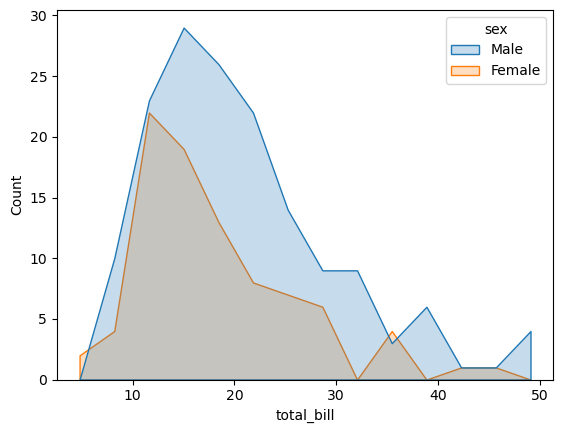

In [7]:
sns.histplot(tips, x='total_bill', hue="sex", element="poly")

<Axes: xlabel='tip', ylabel='Count'>

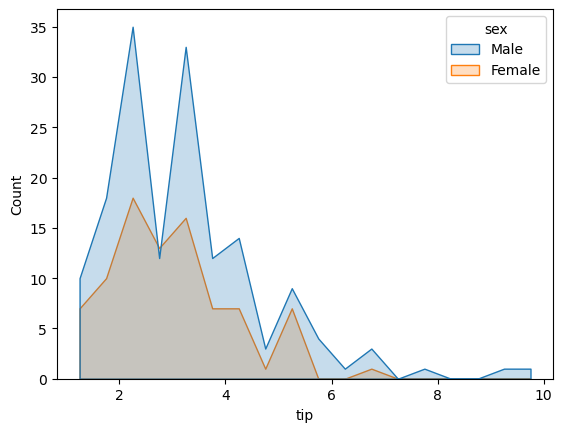

In [8]:
sns.histplot(tips, x='tip', hue="sex", element="poly")

<Axes: xlabel='size', ylabel='Count'>

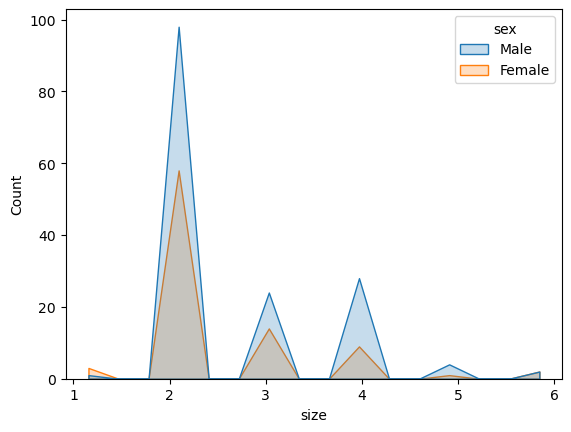

In [9]:
sns.histplot(tips, x='size', hue="sex", element="poly")

<Axes: xlabel='day', ylabel='Count'>

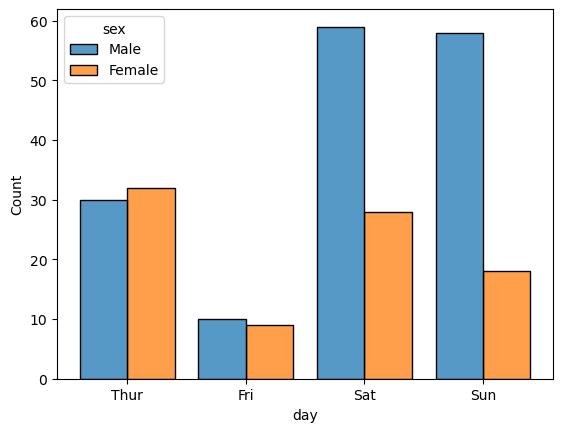

In [10]:
sns.histplot(data=tips, x="day", hue="sex", multiple="dodge", shrink=.8)

<Axes: xlabel='smoker', ylabel='Count'>

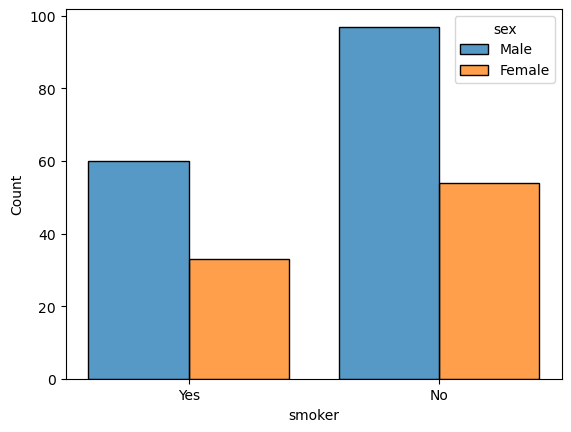

In [11]:
sns.histplot(data=tips, x="smoker", hue="sex", multiple="dodge", shrink=.8)

<Axes: xlabel='time', ylabel='Count'>

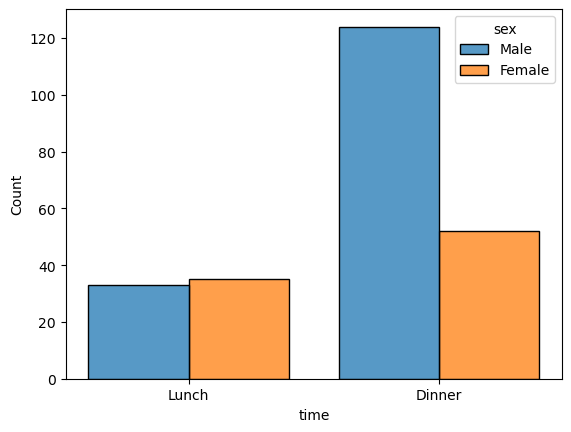

In [12]:
sns.histplot(data=tips, x="time", hue="sex", multiple="dodge", shrink=.8)

## Train-test split

In [13]:
y = tips['sex']
X = tips[['total_bill', 'tip', 'size']]

In [14]:
y.value_counts()

sex
Male      157
Female     87
Name: count, dtype: int64

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0, stratify = y)

# Classification models

More types of classifiers built in scikit learn and their visualizations: https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html

## KNN (K Nearest Neighbors)

https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

### Model training

In [16]:
from sklearn.neighbors import KNeighborsClassifier

In [17]:
knn = KNeighborsClassifier(n_neighbors = 5)

# default n_neighbors = 5

In [18]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### Model evaluation

In [19]:
y_predict = knn.predict(X_test)
y_train_estimated = knn.predict(X_train)

In [20]:
y_predict

array(['Male', 'Female', 'Male', 'Male', 'Male', 'Male', 'Female', 'Male',
       'Female', 'Male', 'Male', 'Male', 'Male', 'Male', 'Male', 'Male',
       'Female', 'Male', 'Male', 'Male', 'Female', 'Male', 'Male', 'Male',
       'Male', 'Male', 'Female', 'Female', 'Male', 'Male', 'Male',
       'Female', 'Male', 'Male', 'Male', 'Male', 'Female', 'Male', 'Male',
       'Male', 'Male', 'Male', 'Female', 'Female', 'Male', 'Male',
       'Female', 'Male', 'Male', 'Female', 'Female', 'Male', 'Male',
       'Male', 'Male', 'Male', 'Female', 'Male', 'Male', 'Female',
       'Female', 'Male', 'Male', 'Male', 'Male', 'Male', 'Male', 'Male',
       'Female', 'Male', 'Male', 'Male', 'Male', 'Male'], dtype=object)

In [21]:
y_test

178    Female
132    Female
226    Female
119    Female
186    Female
        ...  
56       Male
166      Male
73     Female
32     Female
75       Male
Name: sex, Length: 74, dtype: category
Categories (2, object): ['Male', 'Female']

In [22]:
df_test_predict = pd.DataFrame({'y_test': y_test, 'y_predict' : y_predict})
df_test_predict

,y_test,y_predict
178,Female,Male
132,Female,Female
226,Female,Male
119,Female,Male
186,Female,Male
...,...,...
56,Male,Male
166,Male,Male
73,Female,Male
32,Female,Male


#### Evaluation metrics

In [23]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

##### **Accuracy score**

In [24]:
print('Train accuracy: ', accuracy_score(y_train, y_train_estimated))
print('Test accuracy: ', accuracy_score(y_test, y_predict))

Train accuracy:  0.7294117647058823
Test accuracy:  0.5405405405405406


##### **Precision score**

**pos_label** parameter specifies which class should be treated as the "positive" class for binary classification metrics.

Precision is defined as the ratio of True Positives (TP) to all predicted positives $(\text{TP} + \text{False Positives})$.

By setting pos_label='Female', the precision score returned is the model's ability to **correctly identify a 'Female' prediction** when it is making one.

In [25]:
print('Train precision: ',precision_score(y_train, y_train_estimated, pos_label='Female'))
print('Test precision: ',precision_score(y_test, y_predict, pos_label='Female'))

Train precision:  0.6744186046511628
Test precision:  0.2777777777777778


##### **Recall score**

Here, recall represents **the proportion of all actual 'Female' instances that were correctly identified by the model**.

It answers the question: **"Out of all the truly 'Female' people, how many did the model 'recall' or catch?"**

In [26]:
print('Train recall: ',recall_score(y_train, y_train_estimated, pos_label='Female'))
print('Test recall: ',recall_score(y_test, y_predict, pos_label='Female'))

Train recall:  0.47540983606557374
Test recall:  0.19230769230769232


##### **F1 score**

In [27]:
print('Train F1: ',f1_score(y_train, y_train_estimated, pos_label='Female'))
print('Test F1: ',f1_score(y_test, y_predict, pos_label='Female'))

Train F1:  0.5576923076923077
Test F1:  0.22727272727272727


##### **Confusion Matrix**

In [28]:
from sklearn.metrics import confusion_matrix

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

In [29]:
conf_mx_train = confusion_matrix(y_train, y_train_estimated, labels = ['Male', 'Female'])
conf_mx_test = confusion_matrix(y_test, y_predict, labels = ['Male', 'Female'])
conf_mx_test

array([[35, 13],
       [21,  5]])

[None, None]

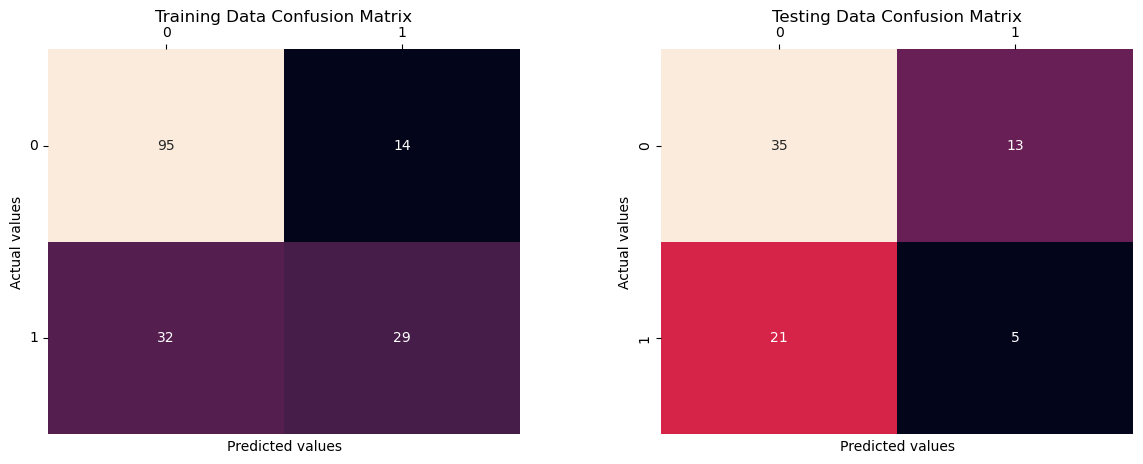

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
plt.subplots_adjust(wspace=0.3)

ax = sns.heatmap(conf_mx_train, annot=True, fmt="d", cbar=False, ax=ax1,)

ax1.set_title('Training Data Confusion Matrix', y=1.05)
ax1.xaxis.tick_top()
ax1.set_xlabel('Predicted values')
ax1.set_ylabel('Actual values')
plt.setp(ax1.get_yticklabels(), rotation=0)

ax = sns.heatmap(conf_mx_test, annot=True, fmt="d", cbar=False, ax=ax2,)

ax2.set_title('Testing Data Confusion Matrix', y=1.05)
ax2.xaxis.tick_top()
ax2.set_xlabel('Predicted values')
ax2.set_ylabel('Actual values')
plt.setp(ax1.get_yticklabels(), rotation=0)

In [31]:
def plot_confusion_matrices(model_name, y_train_true, y_train_pred, y_test_true, y_test_pred, labels=['Male', 'Female']):
    
    conf_mx_train = confusion_matrix(y_train_true, y_train_pred, labels=labels)
    conf_mx_test = confusion_matrix(y_test_true, y_test_pred, labels=labels)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    plt.subplots_adjust(wspace=0.3)
    
    sns.heatmap(conf_mx_train, annot=True, fmt="d", cbar=False, 
                xticklabels=labels, yticklabels=labels, ax=ax1)
    ax1.set_title(f'{model_name} - Training Data')
    ax1.set_xlabel('Predicted')
    ax1.set_ylabel('Actual')
    ax1.xaxis.tick_top()
    ax1.xaxis.set_label_position('top')
    
    sns.heatmap(conf_mx_test, annot=True, fmt="d", cbar=False, cmap="Oranges", 
                xticklabels=labels, yticklabels=labels, ax=ax2)
    ax2.set_title(f'{model_name} - Testing Data')
    ax2.set_xlabel('Predicted')
    ax2.set_ylabel('Actual')
    ax2.xaxis.tick_top()
    ax2.xaxis.set_label_position('top')
    
    plt.show()

#### Validation

In [32]:
def cross_val_results(X, y, model=knn, scoring='accuracy', cv=5):
    scores = cross_val_score(model, X, y, scoring='accuracy', cv=5)

    print(f"Scores: {scores}")
    print(f"Mean: {scores.mean()}")
    print(f"Std: {scores.std()}")
    return scores

In [33]:
cross_val_results(X, y)

Scores: [0.57142857 0.42857143 0.55102041 0.57142857 0.60416667]
Mean: 0.5453231292517006
Std: 0.060809487280749856


array([0.57142857, 0.42857143, 0.55102041, 0.57142857, 0.60416667])

In [34]:
metrics_leaderboard = pd.DataFrame(columns=[
    'Model', 
    'Train Acc', 'Test Acc', 
    'Train Prec', 'Test Prec', 
    'Train Rec', 'Test Rec', 
    'Train F1', 'Test F1',
    'CV F1 Mean', 'CV F1 Std'
])

In [35]:
from sklearn.metrics import make_scorer

In [36]:
def log_and_display_metrics(
        model_name, 
        model, 
        X_train, 
        y_train, 
        X_test, 
        y_test, 
        pos_label='Female', 
        cv=5
        ):
    global metrics_leaderboard
    
  
    f1_scorer = make_scorer(f1_score, pos_label=pos_label, zero_division=0)
    
    cv_scores = cross_val_score(model, X_train, y_train, scoring=f1_scorer, cv=cv)
    
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    new_row = pd.DataFrame({
        'Model': [model_name],
        'Train Acc': [round(accuracy_score(y_train, y_train_pred), 4)],
        'Test Acc': [round(accuracy_score(y_test, y_test_pred), 4)],
        'Train Prec': [round(precision_score(y_train, y_train_pred, pos_label=pos_label, zero_division=0), 4)],
        'Test Prec': [round(precision_score(y_test, y_test_pred, pos_label=pos_label, zero_division=0), 4)],
        'Train Rec': [round(recall_score(y_train, y_train_pred, pos_label=pos_label, zero_division=0), 4)],
        'Test Rec': [round(recall_score(y_test, y_test_pred, pos_label=pos_label, zero_division=0), 4)],
        'Train F1': [round(f1_score(y_train, y_train_pred, pos_label=pos_label, zero_division=0), 4)],
        'Test F1': [round(f1_score(y_test, y_test_pred, pos_label=pos_label, zero_division=0), 4)],
        'CV F1 Mean': [round(cv_scores.mean(), 4)],
        'CV F1 Std': [round(cv_scores.std(), 4)]
    })
    
    metrics_leaderboard = pd.concat([metrics_leaderboard, new_row], ignore_index=True)
    display(metrics_leaderboard)

In [37]:
log_and_display_metrics('KNN (Base)', knn, X_train, y_train, X_test, y_test)

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_85714/209274663.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics_leaderboard = pd.concat([metrics_leaderboard, new_row], ignore_index=True)


,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496


In [38]:
def plot_the_test_results(X_test, y_test, y_predict):
    POS_LABEL = "Female"
    tp_mask = (y_test == POS_LABEL) & (y_predict == POS_LABEL)
    fp_mask = (y_test != POS_LABEL) & (y_predict == POS_LABEL)
    tn_mask = (y_test != POS_LABEL) & (y_predict != POS_LABEL)
    fn_mask = (y_test == POS_LABEL) & (y_predict != POS_LABEL)

    X_test_array = np.array(X_test)
    
    tp_data = X_test_array[tp_mask]
    fp_data = X_test_array[fp_mask]
    tn_data = X_test_array[tn_mask]
    fn_data = X_test_array[fn_mask]

    feature_names = X.columns[:2]
    
    f, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(tn_data[:, 0], tn_data[:, 1], color='green', marker='o', s=60, label='TN: Correct Male', alpha=0.6)
    ax.scatter(tp_data[:, 0], tp_data[:, 1], color='blue', marker='o', s=60, label='TP: Correct Female', alpha=0.6)
    ax.scatter(fn_data[:, 0], fn_data[:, 1], color='red', marker='X', s=100, label='FN: Missed Female', alpha=0.6)
    ax.scatter(fp_data[:, 0], fp_data[:, 1], color='orange', marker='X', s=80, label='FP: Incorrect Female', alpha=0.6)

    ax.set_title(f"Model Classification Performance")
    ax.set_xlabel(f"{feature_names[0]}")
    ax.set_ylabel(f"{feature_names[1]}")
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(title="Prediction Status", loc='best')
    
    plt.show()

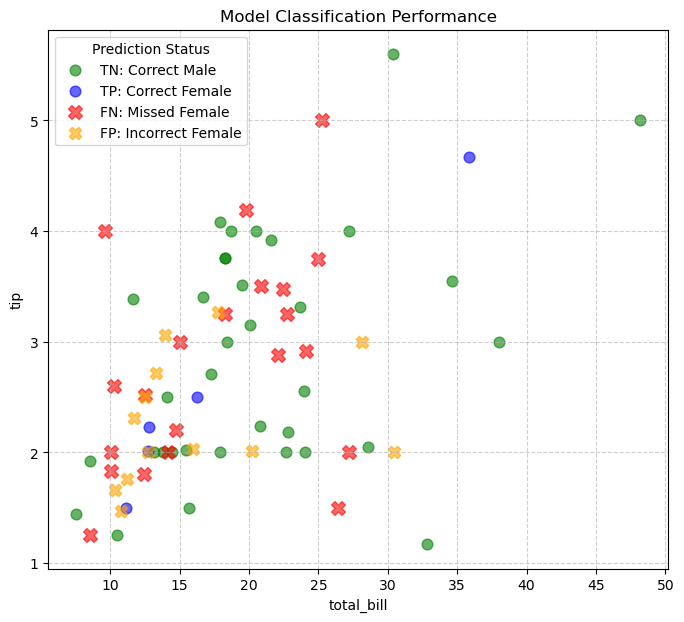

In [39]:
plot_the_test_results(X_test, y_test, y_predict)

### Feature Scaling

In [40]:
norm = MinMaxScaler()
X_norm_train = pd.DataFrame(norm.fit_transform(X_train), columns=X.columns)
X_norm_test = pd.DataFrame(norm.transform(X_test), columns=X.columns)

### Model tuning

Tunable Parameters:

1. $\text{n\_neighbors}$ - Determines the number of closest data points in the training set that are used to vote on the classification of a new data point.
- small n -> High Variance(overfitting)
- large n -> High Bias(underfitting)
2. $\text{metric}$  -> p(default p=2) - Specifies the mathematical formula used to determine "closeness."
- Euclidean(p=2)
- Manhattan(p=1)
- Minkowski(p=2)
- Chebyshev
3. $\text{weights}$ - Determines the influence of each neighbor on the final classification decision.
- Uniform(Default) - All neighbors are weighted equally. A simple majority vote determines the class.
- Distance - Closer neighbors have a greater influence than neighbors further away. The weight is inversely proportional to the distance from the query point. This often improves performance by giving more importance to the most relevant local points.

In [41]:
knn_2 = KNeighborsClassifier(n_neighbors = 3, weights = 'uniform', p = 1)
knn_2.fit(X_norm_train, y_train)
y_predict = knn_2.predict(X_norm_test)
y_train_estimated = knn_2.predict(X_norm_train)

In [42]:
log_and_display_metrics('KNN tuned', knn_2, X_norm_train, y_train, X_norm_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496
1,KNN tuned,0.7706,0.5405,0.6964,0.3571,0.6393,0.3846,0.6667,0.3704,0.3371,0.1609


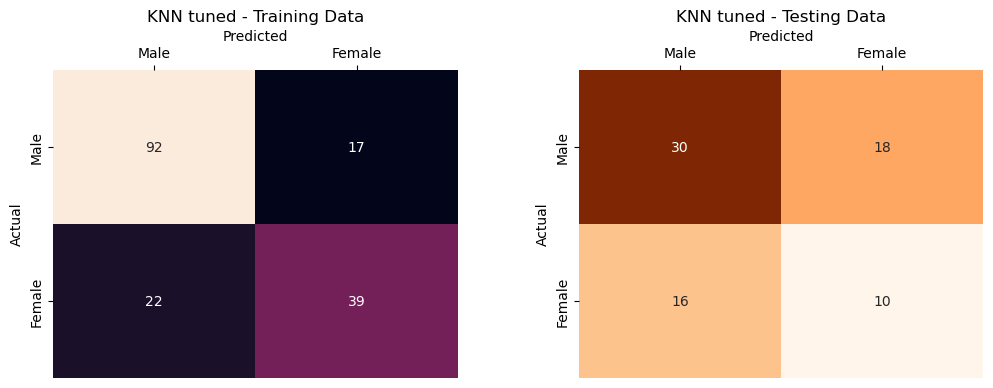

In [43]:
plot_confusion_matrices('KNN tuned', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

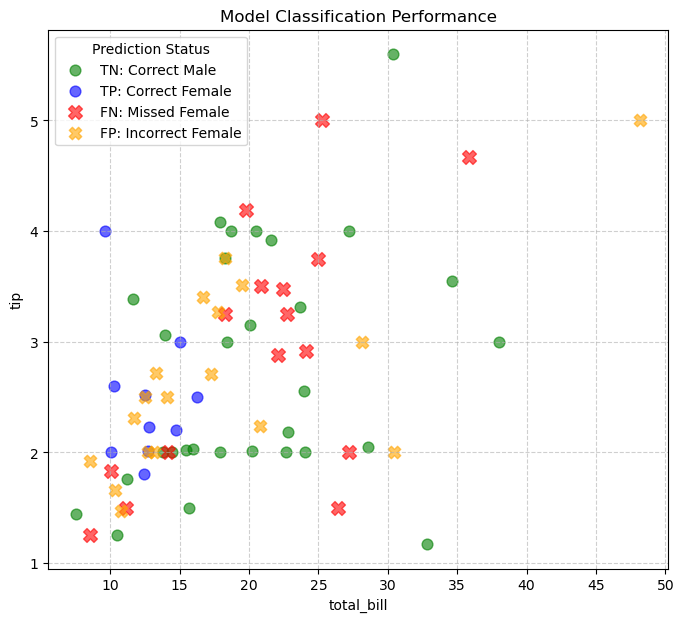

In [44]:
plot_the_test_results(X_test, y_test, y_predict)

## Logistic Regression

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [45]:
from sklearn.linear_model import LogisticRegression

The most important tunable parameters:
- class_weight - used when class imbalance, will favor the underestimated class
- C - by increasing it, will decrease the default penalty (Ridge(L2) and Lasso(L1)

In [46]:
logreg = LogisticRegression(random_state=0, class_weight='balanced', C=1)
logreg.fit(X_norm_train, y_train)
y_predict = logreg.predict(X_norm_test)
y_train_estimated = logreg.predict(X_norm_train)


In [47]:
log_and_display_metrics('LogReg',logreg, X_norm_train, y_train, X_norm_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496
1,KNN tuned,0.7706,0.5405,0.6964,0.3571,0.6393,0.3846,0.6667,0.3704,0.3371,0.1609
2,LogReg,0.5471,0.4595,0.4167,0.3333,0.6557,0.5385,0.5096,0.4118,0.5103,0.0548


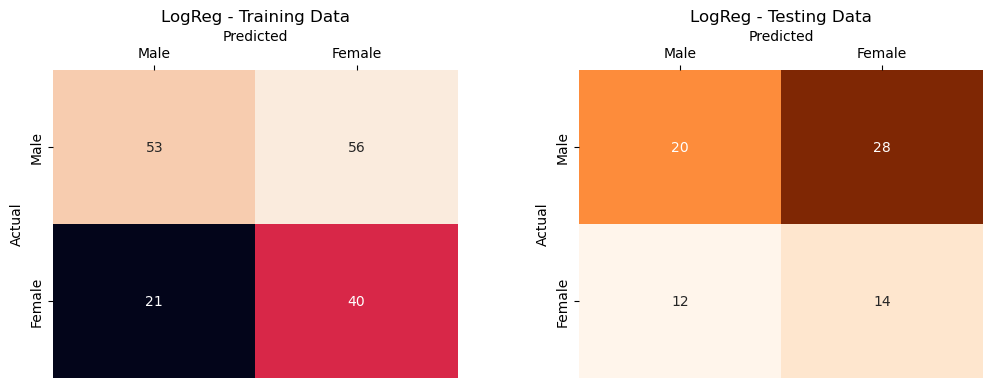

In [48]:
plot_confusion_matrices('LogReg', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

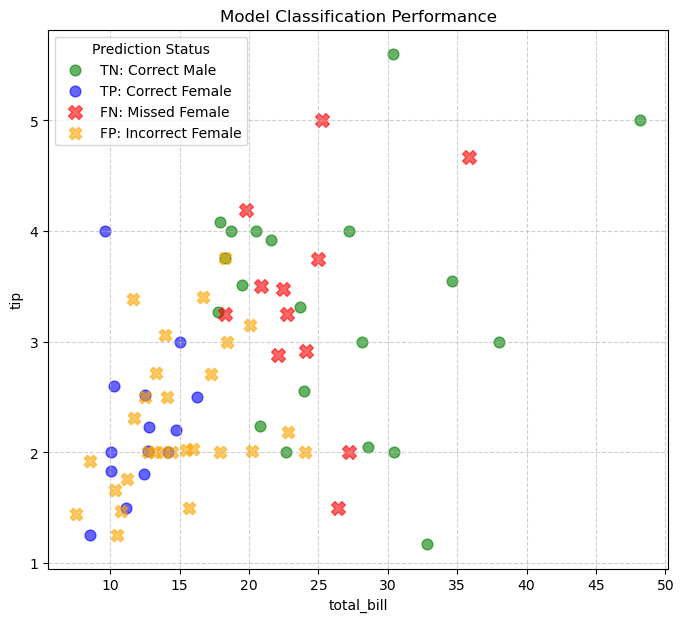

In [49]:
plot_the_test_results(X_test, y_test, y_predict)

## SVC(Support Vector Classification)

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

Also, check out SVR for regression problems: https://scikit-learn.org/stable/auto_examples/svm/plot_svm_regression.html#sphx-glr-auto-examples-svm-plot-svm-regression-py

In [50]:
from sklearn.svm import SVC

The most important tunable parameters:
1. penalty parameter C(default 1) - Regularization parameter. The strength of the regularization is inversely proportional to C.
- Large C(C>10) - High penalty for misclassification. The model focuses heavily on getting every training point right, which often results in a smaller margin and high complexity (potential overfitting).
- Small C(C<1) - Low penalty for misclassification. The model prioritizes a larger margin, allowing more misclassifications (margin violations) in the training data, leading to a smoother boundary (potential underfitting).

2. Kernel type
- 'linear' - Finds the optimal linear separating hyperplane. Fastest, simplest, and best when the data is linearly separable.
- 'poly' - Uses a polynomial function. Requires tuning the $\text{degree}$ parameter. Requires tuning the 
 parameter.
- 'rbf'($\text{Radial Basis Function}$)(default) - The most common non-linear kernel. It maps samples non-linearly to an infinite-dimensional space. Requires tuning the $\gamma$ parameter.
- 'sigmoid' - Uses the hyperbolic tangent function. Requires tuning the $\gamma$ parameter.

3. Kernel Coefficient ($\mathbf{gamma}$ or $\gamma$) - defines how far the influence of a single training example reaches. Conceptually, it determines the "reach" or curvature of the decision boundary.
- Large $\gamma$ (>1) - High influence of individual training points. Results in a highly complex, rugged decision boundary (potential overfitting). The decision boundary is heavily influenced by points very close to it.
- Small $\gamma$ (<1) - Low influence of individual points. Results in a smoother, more global decision boundary (potential underfitting).

4. Degree(for 'poly') - used to calculate the decision boundary. Higher degrees (e.g., $\text{degree}=3$ or $4$) create more complex, curved boundaries, increasing the risk of overfitting. Lower degrees keep the model simpler.

5. class_weight - is crucial when dealing with imbalanced classification problems. Used to assign different penalties to misclassification errors for different classes. Setting it to $\text{'balanced'}$ automatically adjusts weights inversely proportional to class frequencies in the training data. 

In our case we will: 
- Set the class_weight parameter to 'balanced'.
- To reduce overfitting - will increase the margins, and reduce complexity - smaller C -> C=0.1 or C=0.5 - A smaller C allows for more margin violations, leading to a smoother, more generalized decision boundary.

In [51]:
svc_clf = SVC(class_weight='balanced', C=0.5)
svc_clf.fit(X_norm_train, y_train)

y_predict = svc_clf.predict(X_norm_test)
y_train_estimated = svc_clf.predict(X_norm_train)



In [52]:
log_and_display_metrics('SVC', svc_clf, X_norm_train, y_train, X_norm_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496
1,KNN tuned,0.7706,0.5405,0.6964,0.3571,0.6393,0.3846,0.6667,0.3704,0.3371,0.1609
2,LogReg,0.5471,0.4595,0.4167,0.3333,0.6557,0.5385,0.5096,0.4118,0.5103,0.0548
3,SVC,0.5882,0.4730,0.4579,0.3488,0.8033,0.5769,0.5833,0.4348,0.5189,0.0569


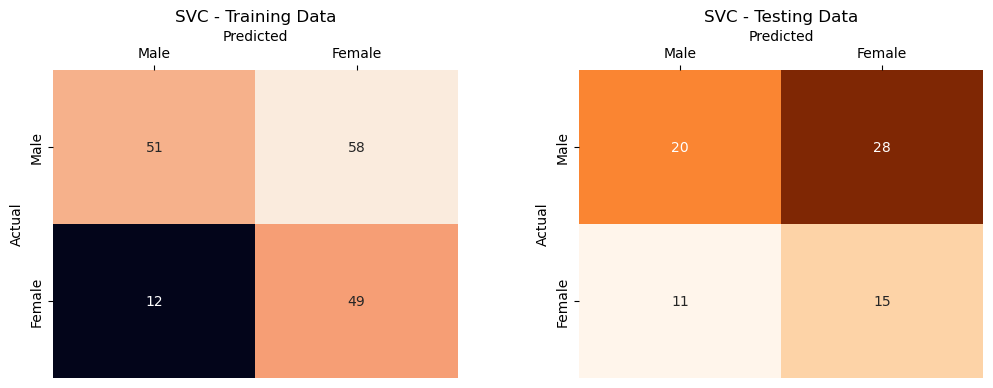

In [53]:
plot_confusion_matrices('SVC', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

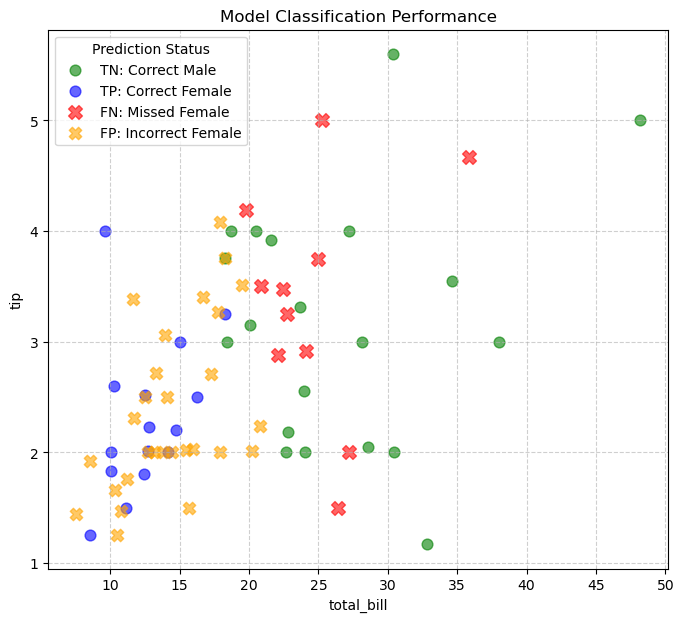

In [54]:
plot_the_test_results(X_test, y_test, y_predict)

## Naive Bayes

In [55]:
from sklearn.naive_bayes import GaussianNB

- $\mathbf{var\_smoothing}$ - a positive value added to the variances of all features during the calculation of likelihood. It's often referred to as Laplace smoothing or additive smoothing. It addresses the problem of zero variance in a feature for a specific class. If the variance of a feature is zero, the model might assign an impossible probability of zero to a new data point, causing classification failure. Adding this tiny value stabilises the model.

In [56]:
y.value_counts(normalize = True)

sex
Male      0.643443
Female    0.356557
Name: proportion, dtype: float64

In [57]:
gnb = GaussianNB(priors = [0.65, 0.35])

gnb.fit(X_norm_train, y_train)

y_predict = gnb.predict(X_norm_test)
y_train_estimated = gnb.predict(X_norm_train)

In [58]:
log_and_display_metrics('GaussNB', gnb, X_norm_train, y_train, X_norm_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496
1,KNN tuned,0.7706,0.5405,0.6964,0.3571,0.6393,0.3846,0.6667,0.3704,0.3371,0.1609
2,LogReg,0.5471,0.4595,0.4167,0.3333,0.6557,0.5385,0.5096,0.4118,0.5103,0.0548
3,SVC,0.5882,0.4730,0.4579,0.3488,0.8033,0.5769,0.5833,0.4348,0.5189,0.0569
4,GaussNB,0.4529,0.3784,0.3857,0.3529,0.8852,0.9231,0.5373,0.5106,0.5118,0.0159


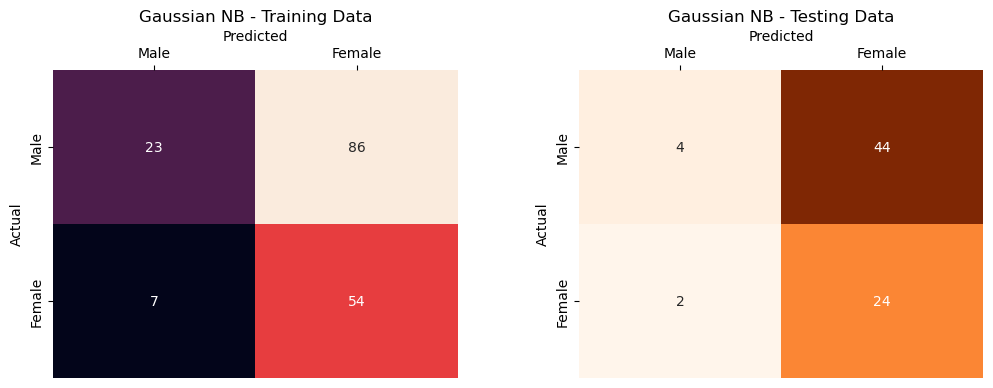

In [59]:
plot_confusion_matrices('Gaussian NB', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

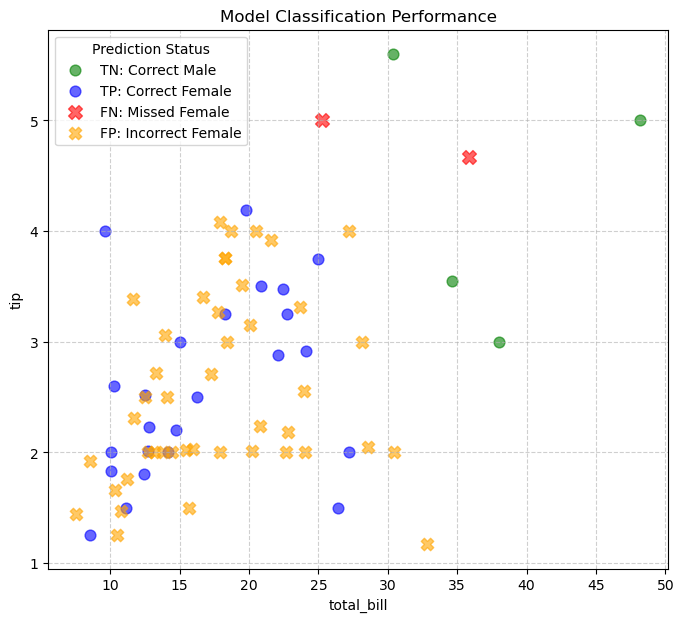

In [60]:
plot_the_test_results(X_test, y_test, y_predict)

## Decision Tree

In [61]:
from sklearn.tree import DecisionTreeClassifier

In [62]:
dt = DecisionTreeClassifier()  
dt.fit(X_train, y_train)

y_predict = dt.predict(X_test)
y_train_estimated = dt.predict(X_train)

In [63]:
X.columns

Index(['total_bill', 'tip', 'size'], dtype='object')

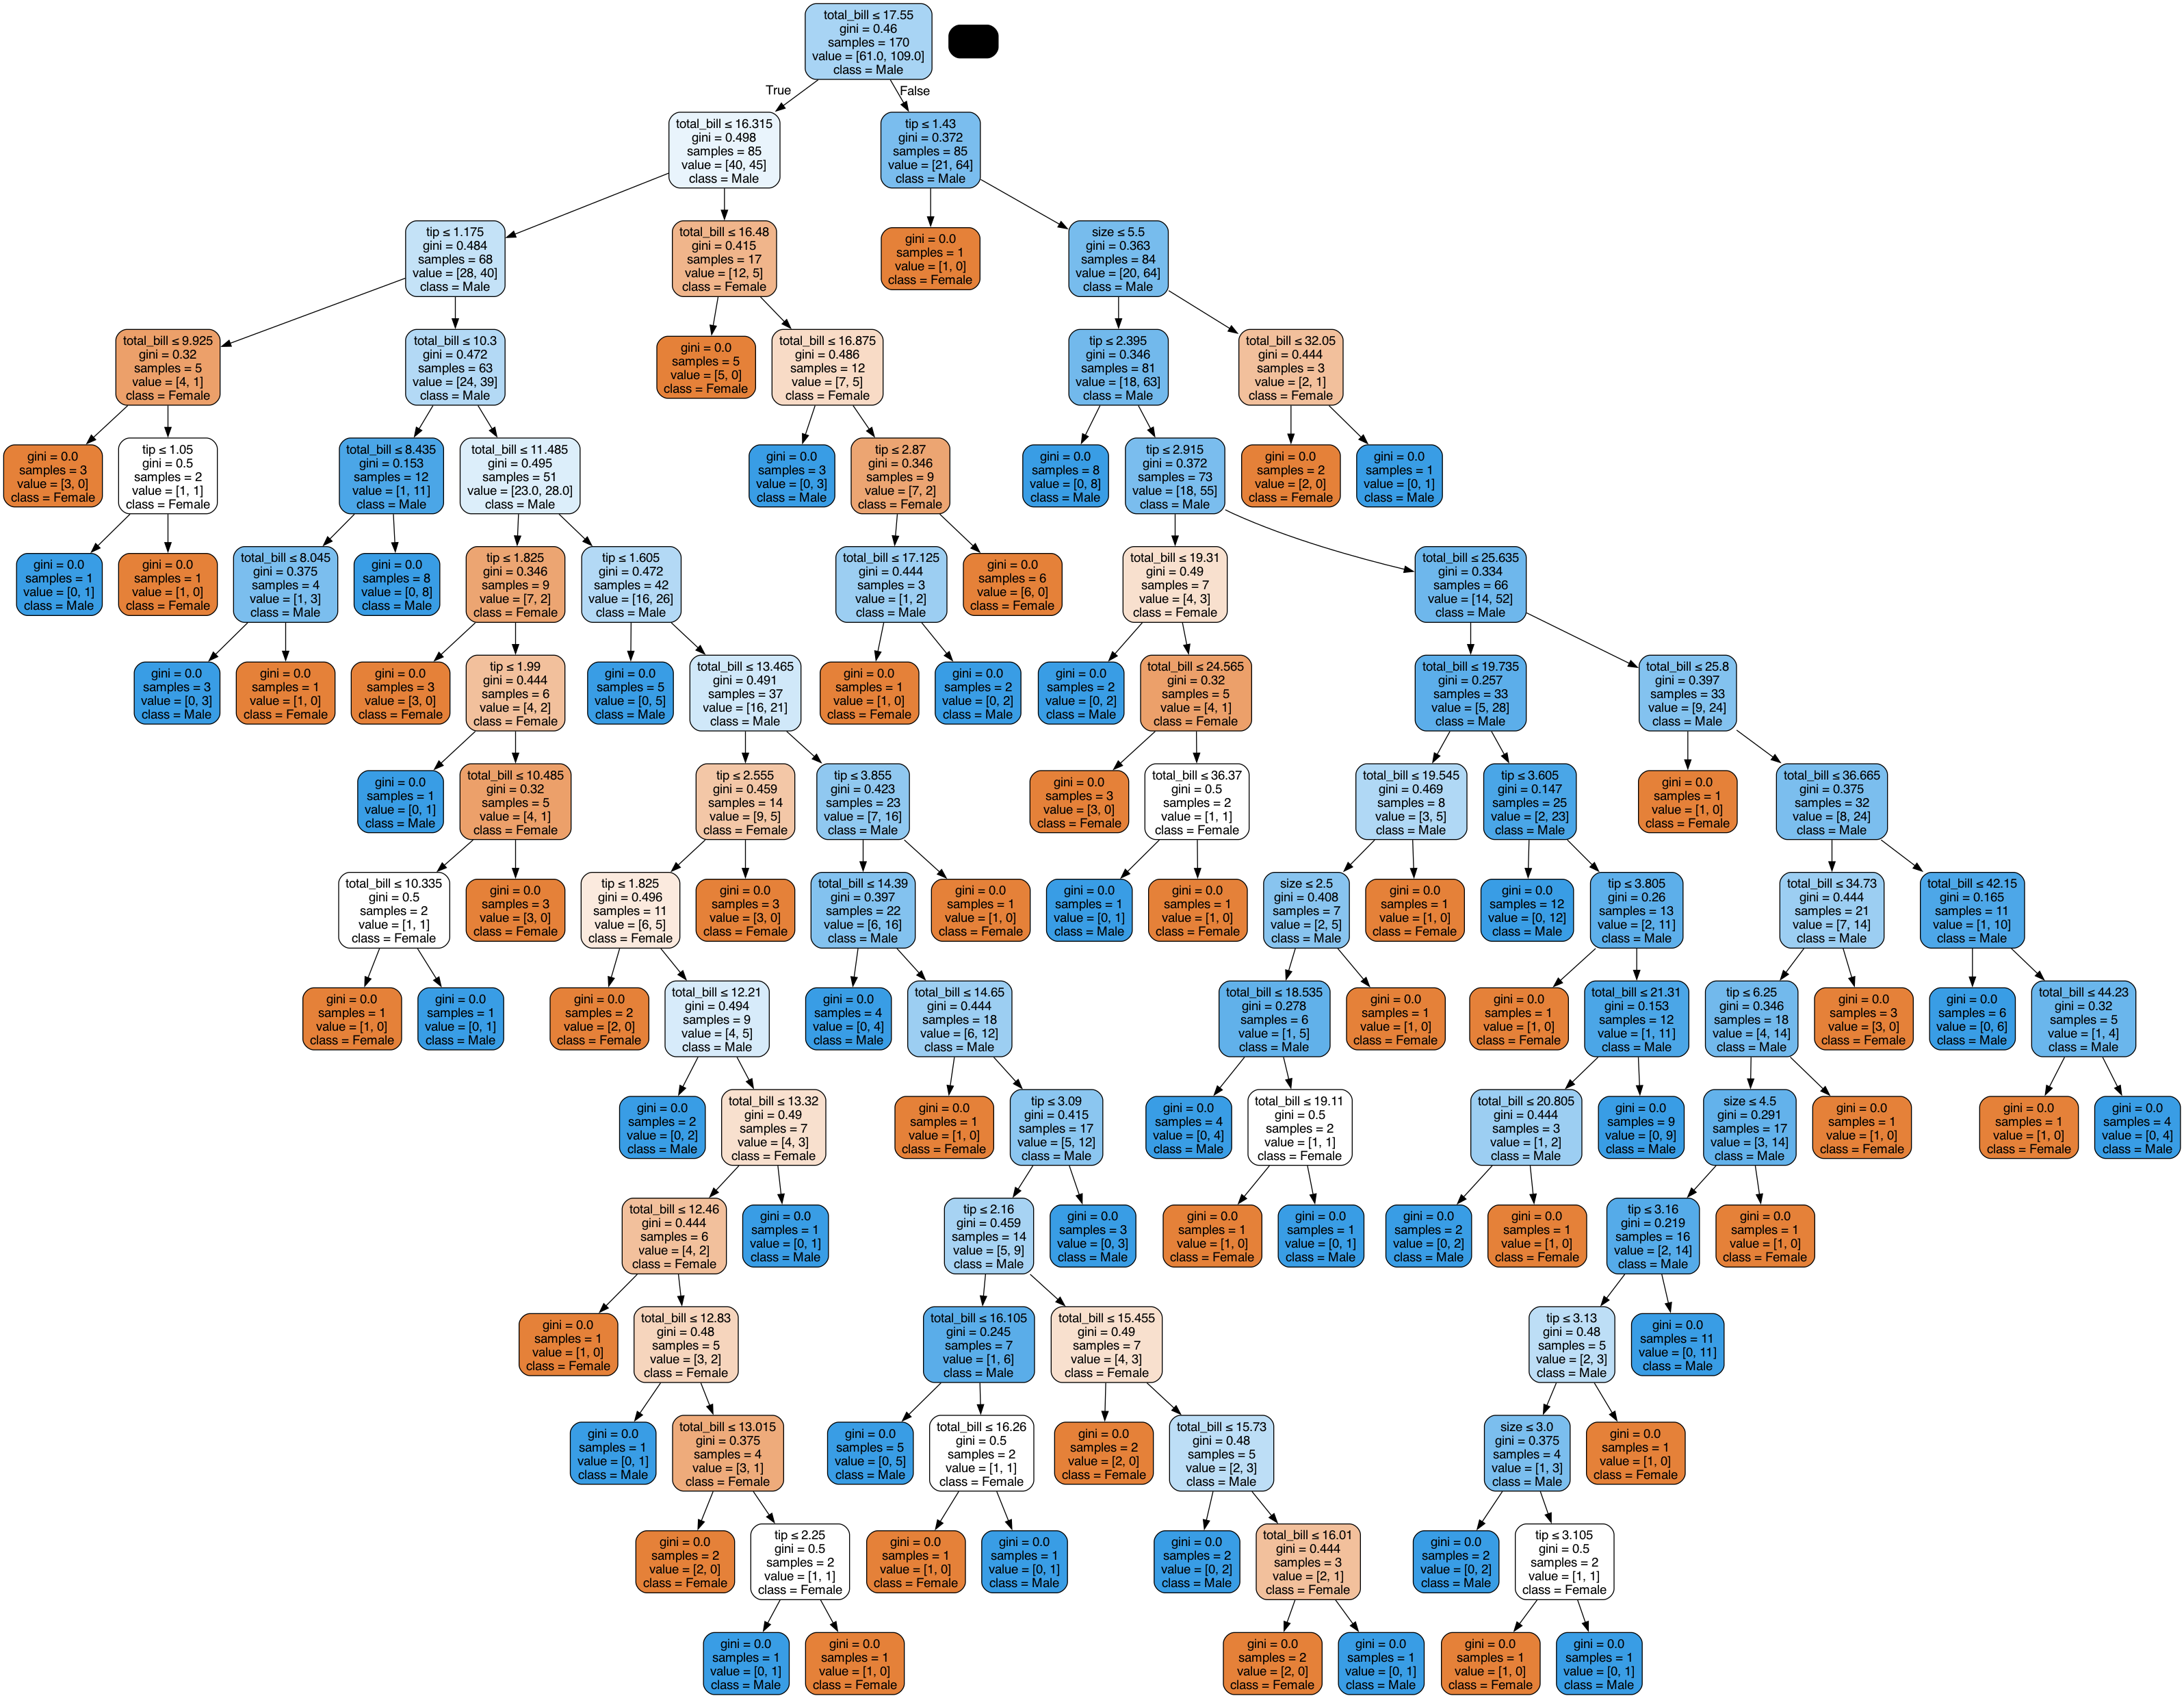

In [ ]:
from sklearn.tree import export_graphviz
from six import StringIO  
from IPython.display import Image  
import pydotplus

dot_data = StringIO()
export_graphviz(dt, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X.columns,
                class_names=["Female", "Male"])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('tips.png')
Image(graph.create_png())

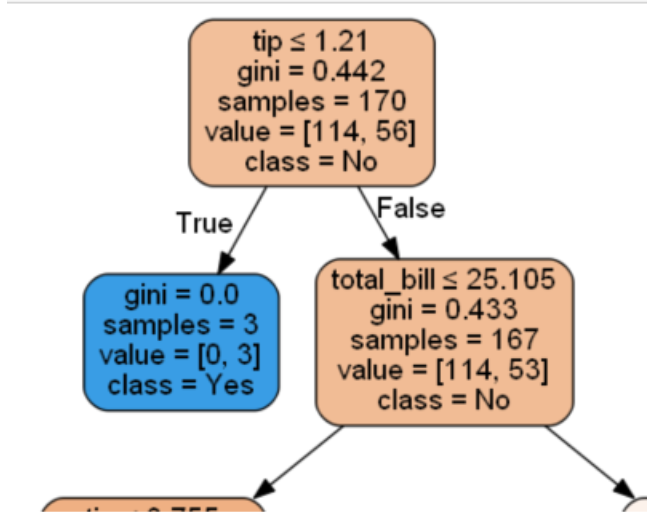

In [65]:
log_and_display_metrics('DT', dt, X_train, y_train, X_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496
1,KNN tuned,0.7706,0.5405,0.6964,0.3571,0.6393,0.3846,0.6667,0.3704,0.3371,0.1609
2,LogReg,0.5471,0.4595,0.4167,0.3333,0.6557,0.5385,0.5096,0.4118,0.5103,0.0548
3,SVC,0.5882,0.4730,0.4579,0.3488,0.8033,0.5769,0.5833,0.4348,0.5189,0.0569
4,GaussNB,0.4529,0.3784,0.3857,0.3529,0.8852,0.9231,0.5373,0.5106,0.5118,0.0159
5,DT,1.0000,0.5676,1.0000,0.3500,1.0000,0.2692,1.0000,0.3043,0.3662,0.1226


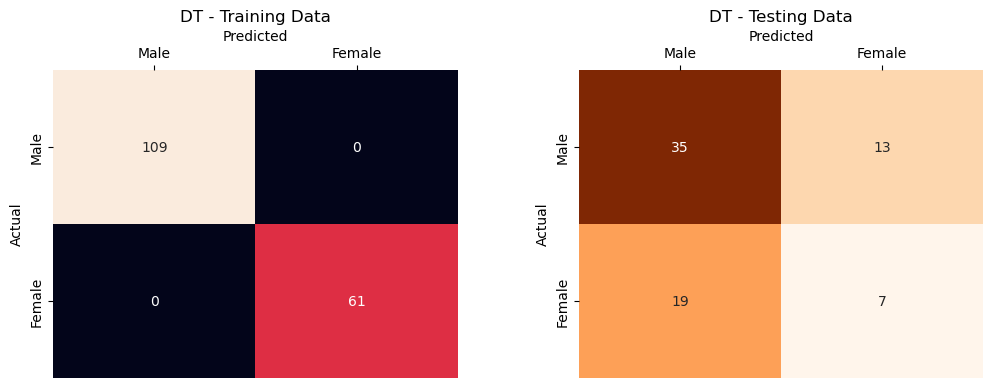

In [66]:
plot_confusion_matrices('DT', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

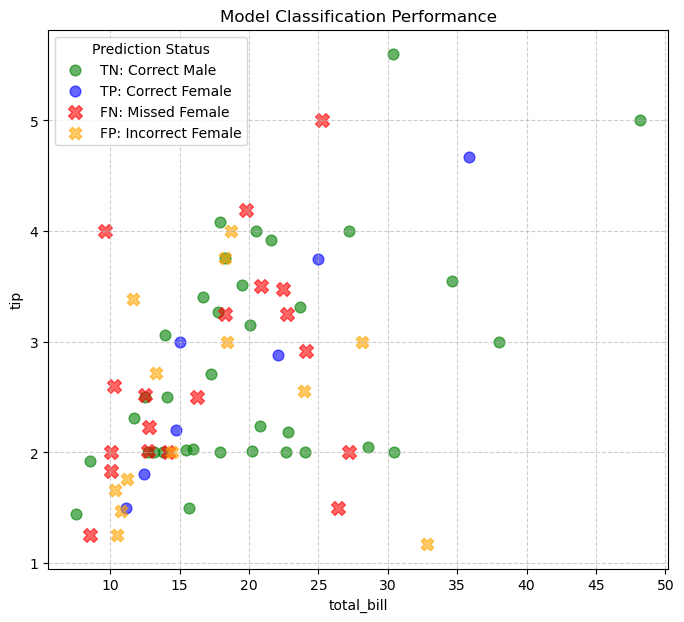

In [67]:
plot_the_test_results(X_test, y_test, y_predict)

### Model tuning

- criterion: gini/entropy
- max_depth - Limits the number of levels (splits) the tree can grow below the root node.
- min_samples_leaf -Defines the minimum number of samples that must be present in a new leaf node after a split occurs.
- min_samples_split - Defines the minimum number of samples required to be present in a node for it to be eligible for a split.
- class_weight

See more parameters here:
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier

In [68]:
dt_2 = DecisionTreeClassifier(criterion = 'entropy', 
                              class_weight = 'balanced', 
                              max_depth = 20, 
                              min_samples_leaf = 10)  

dt_2.fit(X_train, y_train)

y_predict = dt_2.predict(X_test)
y_train_estimated = dt_2.predict(X_train)

In [69]:
log_and_display_metrics('DT Tuned', dt_2, X_train, y_train, X_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,KNN (Base),0.7294,0.5405,0.6744,0.2778,0.4754,0.1923,0.5577,0.2273,0.2411,0.0496
1,KNN tuned,0.7706,0.5405,0.6964,0.3571,0.6393,0.3846,0.6667,0.3704,0.3371,0.1609
2,LogReg,0.5471,0.4595,0.4167,0.3333,0.6557,0.5385,0.5096,0.4118,0.5103,0.0548
3,SVC,0.5882,0.4730,0.4579,0.3488,0.8033,0.5769,0.5833,0.4348,0.5189,0.0569
4,GaussNB,0.4529,0.3784,0.3857,0.3529,0.8852,0.9231,0.5373,0.5106,0.5118,0.0159
5,DT,1.0000,0.5676,1.0000,0.3500,1.0000,0.2692,1.0000,0.3043,0.3662,0.1226
6,DT Tuned,0.6824,0.4865,0.5432,0.3125,0.7213,0.3846,0.6197,0.3448,0.4720,0.1286


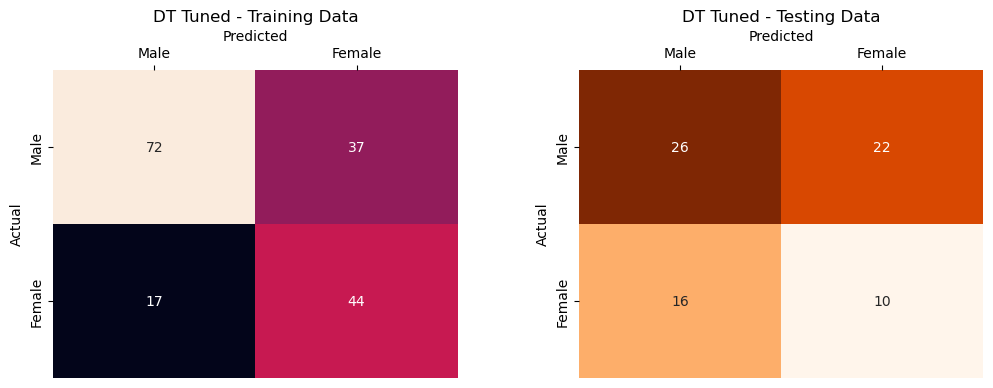

In [70]:
plot_confusion_matrices('DT Tuned', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

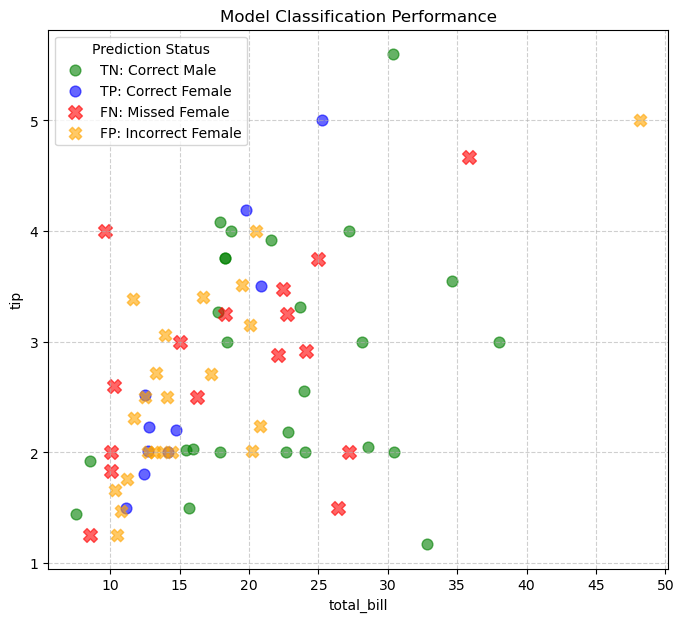

In [71]:
plot_the_test_results(X_test, y_test, y_predict)

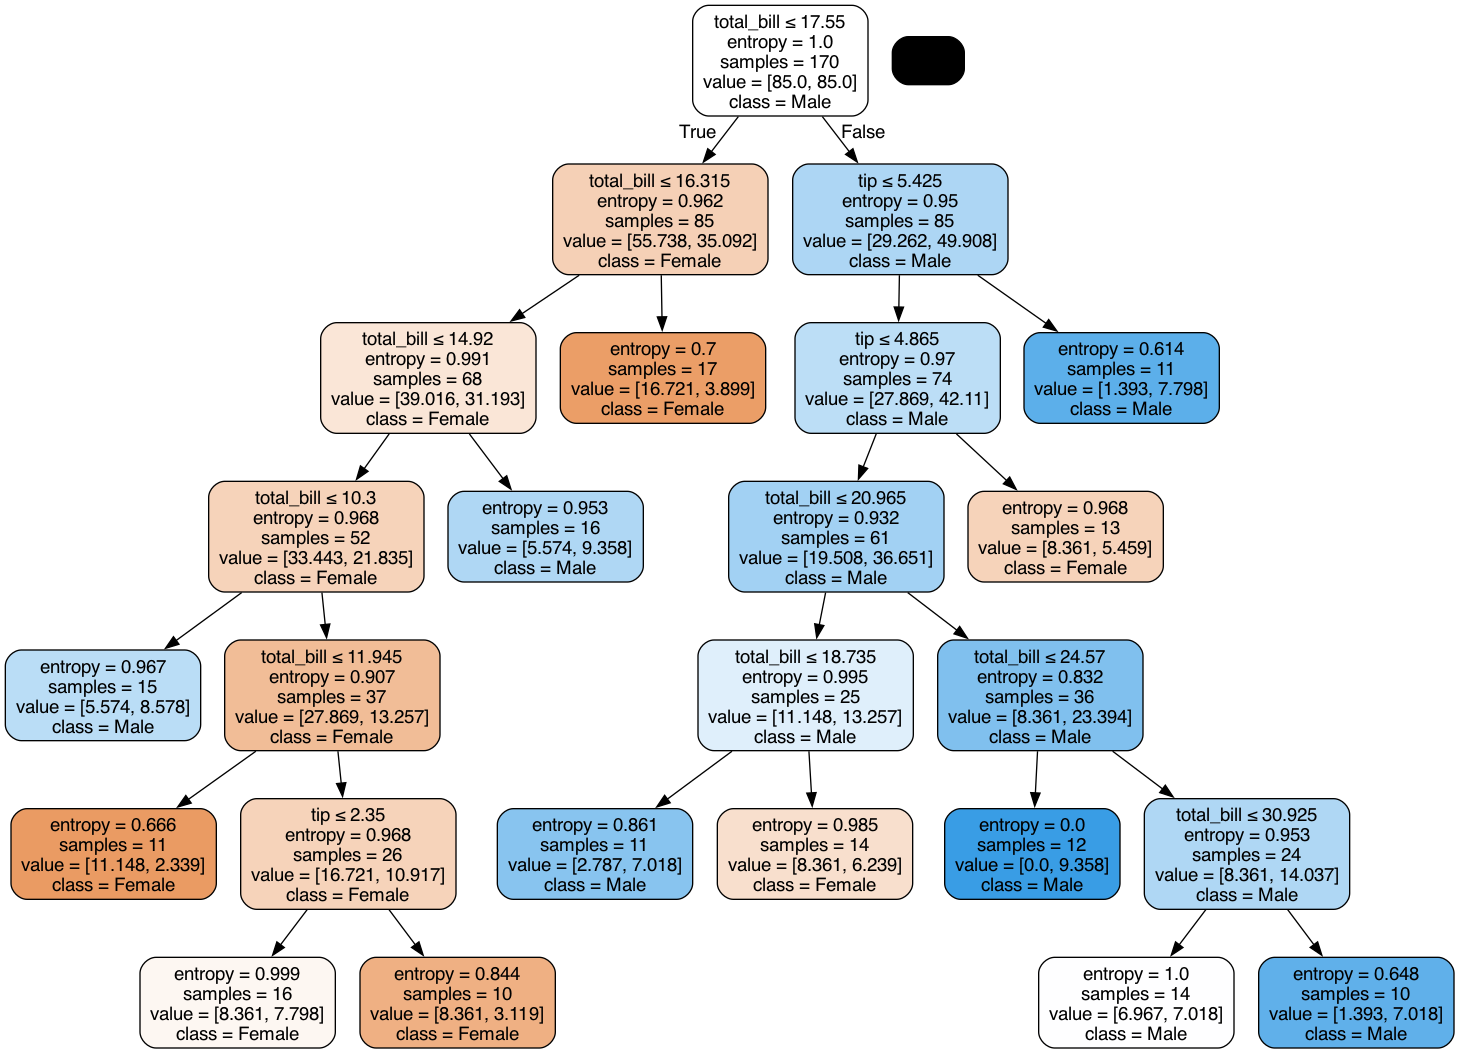

In [72]:
from sklearn.tree import export_graphviz
from six import StringIO  
from IPython.display import Image  
import pydotplus

dot_data = StringIO()
export_graphviz(dt_2, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X.columns,
                class_names=["Female", "Male"])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('diabetes.png')
Image(graph.create_png())

**Optional OTJ task: Feel free to perform feature engineering, convert the categorical columns into dummy columns, and try to train the models from above.**